# Лабораторная работа 15. Генерация на LFW
Реальный короткий CPU-опыт VAE и GAN на непересекающихся группах людей. Данные должны иметь структуру identity/identity_0001.jpg. По умолчанию используется temp/lfw-textbook; задайте LFW_TEXTBOOK_DIR для другого кэша. Полная проверенная процедура приобретения и ограничения зеркальной подвыборки описаны в главе и лабораторной. Notebook не публикует исходные фотографии.

In [1]:
from pathlib import Path
import os,sys
from tempfile import gettempdir
here=Path.cwd().resolve()
candidates=[entry for parent in (here,*here.parents) for entry in (parent,parent/'Deep_Learning_Textbook')]
book=next(entry for entry in candidates if (entry/'Python_Code/Chapter_15').is_dir())
sys.path.insert(0,str(book/'Python_Code/Chapter_15'))
import torch
from lfw_generation import main,diagnostics,read_lfw
torch.set_num_threads(2)
samples=torch.tensor([[.4,.6],[.5,.5]],dtype=torch.float64)
train=torch.tensor([[.4,.6],[.1,.2]],dtype=torch.float64)
heldout=torch.tensor([[.5,.5],[.8,.8]],dtype=torch.float64)
check=diagnostics(samples,train,heldout)
for key,expected in [('nearest_train_mse',.005),('nearest_heldout_mse',.005),('sample_pair_mse',.01)]:
    assert abs(check[key]-expected)<1e-12,(key,check)
print('Числовой пример:',check)
directory=Path(os.environ.get('LFW_TEXTBOOK_DIR',Path(gettempdir())/'lfw-textbook'))
print('Локальные данные:',directory)

Числовой пример: {'reference_size': 2, 'nearest_train_mse': 0.0049999999999999975, 'nearest_heldout_mse': 0.0049999999999999975, 'sample_pair_mse': 0.009999999999999997}
Локальные данные: <локальный каталог>


In [2]:
result=main(['--lfw-dir',str(directory),'--epochs','1'])
assert result['sizes']['train']>0 and result['sizes']['val']>0 and result['sizes']['test']>0
print('Короткий протокол: одна эпоха, одинаковые групповые части для VAE и GAN')

torch=2.10.0+cpu cpu seed=2026 crop=central60% grayscale32x32 epochs=1
identities train=230 val=49 test=50
images train=306 val=80 test=69


epoch=1 recon_bce=715.247768 kl=0.553150 discriminator=0.674087 generator=0.852698
validation vae_mu_mse=0.056704 vae_mu_bce=708.633545 vae_kl=0.809113
test vae_mu_mse=0.059673 vae_mu_bce=708.666504 vae_kl=0.841519
VAE reference_size=64.000000 nearest_train_mse=0.015961 nearest_heldout_mse=0.021176 sample_pair_mse=0.004938
GAN reference_size=64.000000 nearest_train_mse=0.017362 nearest_heldout_mse=0.023859 sample_pair_mse=0.005524
Короткий протокол: одна эпоха, одинаковые групповые части для VAE и GAN


In [3]:
for name in ('vae','gan'):
    assert result[name].shape==(16,1024)
    assert torch.isfinite(result[name]).all()
    assert ((result[name]>=0)&(result[name]<=1)).all()
data,people=read_lfw(directory,seed=2026)
assert people==result['identities']
assert {key:len(value) for key,value in data.items()}==result['sizes']
# Независимо пересчитываем первый ближайший MSE прямым циклом.
value=result['vae'][0]
reference=data['test'][:64]
explicit=min(float((value-row).square().mean()) for row in reference)
vectorized=float((value[None,:]-reference).square().mean(dim=1).min())
assert abs(explicit-vectorized)<1e-8
print('Проверены формы, диапазоны, конечность и независимый пересчёт расстояния',explicit)

Проверены формы, диапазоны, конечность и независимый пересчёт расстояния 0.020926259458065033


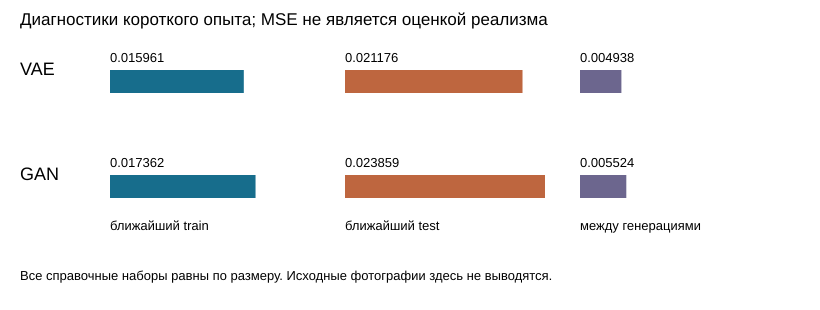

In [4]:
from IPython.display import SVG,display
colors=['#176d8c','#be663f','#6c668e']
labels=['ближайший train','ближайший test','между генерациями']
fields=['nearest_train_mse','nearest_heldout_mse','sample_pair_mse']
maximum=max(result['diagnostics'][name][key] for name in ('VAE','GAN') for key in fields)
pieces=['<svg xmlns="http://www.w3.org/2000/svg" width="820" height="310"><rect width="100%" height="100%" fill="white"/>']
pieces.append('<text x="20" y="25" font-family="Arial" font-size="17">Диагностики короткого опыта; MSE не является оценкой реализма</text>')
for row,name in enumerate(('VAE','GAN')):
    pieces.append(f'<text x="20" y="{75+row*105}" font-family="Arial" font-size="18">{name}</text>')
    for col,(field,label,color) in enumerate(zip(fields,labels,colors)):
        x=110+col*235;y=70+row*105;value=result['diagnostics'][name][field]
        pieces.append(f'<rect x="{x}" y="{y}" width="{200*value/maximum:.2f}" height="23" fill="{color}"/>')
        pieces.append(f'<text x="{x}" y="{y-8}" font-family="Arial" font-size="13">{value:.6f}</text>')
        if row==1:
            pieces.append(f'<text x="{x}" y="230" font-family="Arial" font-size="13">{label}</text>')
pieces.append('<text x="20" y="280" font-family="Arial" font-size="13">Все справочные наборы равны по размеру. Исходные фотографии здесь не выводятся.</text></svg>')
display(SVG(''.join(pieces)))

## Работа с результатами
Отделите reconstruction VAE от независимых prior-выборок. Повторите полный протокол на трёх заранее заданных seed и сохраните все результаты. Не используйте test для выбора числа эпох. Малая MSE к train сама по себе не доказывает запоминание, а высокая попарная MSE сама по себе не доказывает разнообразие семантики. Сравните с контролем из случайного шума и объясните пределы вывода.